In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import os
import sys

# Garante que o python ache os módulos
repo_root = os.path.abspath("..")
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

from tools import utils
from tools import radii_skewers 

# Estilo visual
plt.rcdefaults()
plt.style.use('tableau-colorblind10')
%matplotlib widget 

plt.rcParams.update({
    'font.size': 10,
    'axes.labelsize': 11,
    'figure.titlesize': 12,
    # Garante que textos apareçam bem em fundo preto se o notebook estiver em dark mode
    'text.color': 'black', 
    'axes.labelcolor': 'black',
    'xtick.color': 'black',
    'ytick.color': 'black',
})

In [2]:
%autoreload

In [3]:
# --- 1. CONFIGURAÇÃO ---
SNAP_NUM = "264"
MATCH_INDEX = 250   
XMATCH_DIR = "../xmatchs" # Caminho onde estão os .npy
PATH_SIM = "/home/STORAGE/MN5_resims/fiducial/hydro_output"

# IMPORTANTE: O nome do arquivo é 'xmatch_fiducial_0.npy' (minúsculo)
# Mas talvez você queira rodar para o LH_0.
# Se o arquivo for 'xmatch_LH_0.npy', use SIM_NAME = "LH_0"
SIM_NAME = "fiducial" 

# --- 2. PARÂMETROS DA ANÁLISE ---
# Aqui você escolhe a distância como multiplicador do R200!
R200_MULTIPLIER = 0.5  # Ex: 0.5 (metade do raio), 1.0 (na borda), 2.0 (longe)

# --- 3. INICIALIZAÇÃO ---
print(f"--> Iniciando análise para {SIM_NAME}, Halo Index {MATCH_INDEX}")

matcher = utils.HaloMatcher(XMATCH_DIR)
ctx = utils.SimulationContext(PATH_SIM, SNAP_NUM)
halo_finder = utils.HaloFinder(ctx)

# Pega o ID e Propriedades Básicas
try:
    halo_id = matcher.get_halo_id(SIM_NAME, MATCH_INDEX)
    halo_info = halo_finder.get_halo_properties(halo_id)
    print(f"--> Halo ID Encontrado: {halo_id}")
    print(f"--> Posição Central (Mpc/h): {halo_info['cm']}")
except Exception as e:
    print(f"ERRO CRÍTICO: {e}")
    # Fallback manual para teste se o match falhar
    print("Tentando Halo ID 0 manualmente...")
    halo_id = 0
    halo_info = halo_finder.get_halo_properties(0)

# --- 4. PREPARAR GEOMETRIA DOS SKEWERS ---
# Inicializa o gerador que tem a correção do R200
geom = radii_skewers.SkewerGeometry(ctx, halo_info)

# Gera os 12 skewers (4 em X, 4 em Y, 4 em Z)
skewers_list = geom.generate_12_skewers(r_multiplier=R200_MULTIPLIER)

print(f"--> Geometria gerada: {len(skewers_list)} skewers.")
print(f"--> R200 do Halo: {geom.r200_mpc:.3f} Mpc/h")
print(f"--> Raio de Impacto: {skewers_list[0]['impact_mpc']:.3f} Mpc/h")

# --- 5. CARREGAR GÁS (SLICE 50 Mpc) ---
# Carregamos uma fatia grossa para ver a estrutura cósmica, mas não a caixa toda em Z para poupar RAM
slice_thickness = 100.0 # Mpc/h
box_size = halo_info['box_size']

print(f"--> Carregando Gás (Slice {slice_thickness} Mpc/h)... isso pode demorar um pouco.")
gas_loader = utils.GasLoader(ctx)

# O utils carrega e já centraliza nas coordenadas periódicas? 
# Vamos verificar o código do utils: ele faz `_apply_pbc_shift`.
# Isso significa que o HALO estará em (0,0,0) nas coordenadas retornadas.
gas_map_centered = gas_loader.load_gas_slice(halo_info['cm'], box_size, slice_thickness=slice_thickness)

print(f"--> Partículas carregadas: {gas_map_centered.shape[0]}")

2026-02-10 10:59:41,725 - INFO - Loading match catalog for fiducial...
2026-02-10 10:59:41,726 - INFO - Halo 928 | R200_Crit = 0.1188 cMpc/h


--> Iniciando análise para fiducial, Halo Index 250
--> Halo ID Encontrado: 928
--> Posição Central (Mpc/h): [216.42542 132.15091 264.58994]
--> Geometria gerada: 12 skewers.
--> R200 do Halo: 0.119 Mpc/h
--> Raio de Impacto: 0.059 Mpc/h
--> Carregando Gás (Slice 100.0 Mpc/h)... isso pode demorar um pouco.
--> Partículas carregadas: 19440369


--> Gerando espectros sintéticos...
Reloading from snapshot (will save to:  /home/STORAGE/MN5_resims/fiducial/hydro_output/snapdir_264/temp_skewer_928_8494.hdf5  )
1  sightlines. resolution:  10.002000400080014  z= 4.440892098500626e-16
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done


2026-02-10 11:00:07,601 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


Reloading from snapshot (will save to:  /home/STORAGE/MN5_resims/fiducial/hydro_output/snapdir_264/temp_skewer_928_34514.hdf5  )
1  sightlines. resolution:  10.002000400080014  z= 4.440892098500626e-16
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done


2026-02-10 11:00:27,124 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


Reloading from snapshot (will save to:  /home/STORAGE/MN5_resims/fiducial/hydro_output/snapdir_264/temp_skewer_928_20317.hdf5  )
1  sightlines. resolution:  10.002000400080014  z= 4.440892098500626e-16
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done


2026-02-10 11:00:47,952 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


... (15 outputs left out)

2026-02-10 11:03:33,997 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


Reloading from snapshot (will save to:  /home/STORAGE/MN5_resims/fiducial/hydro_output/snapdir_264/temp_skewer_928_48909.hdf5  )
1  sightlines. resolution:  10.002000400080014  z= 4.440892098500626e-16
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 25.0 percent done
rank = 0 | Interpolation 37.5 percent done
rank = 0 | Interpolation 50.0 percent done
rank = 0 | Interpolation 62.5 percent done
rank = 0 | Interpolation 75.0 percent done
rank = 0 | Interpolation 87.5 percent done


2026-02-10 11:03:54,905 - INFO - Isolation applied: R=11.88 Mpc/h. N_HI calculated.


--> Plotando...


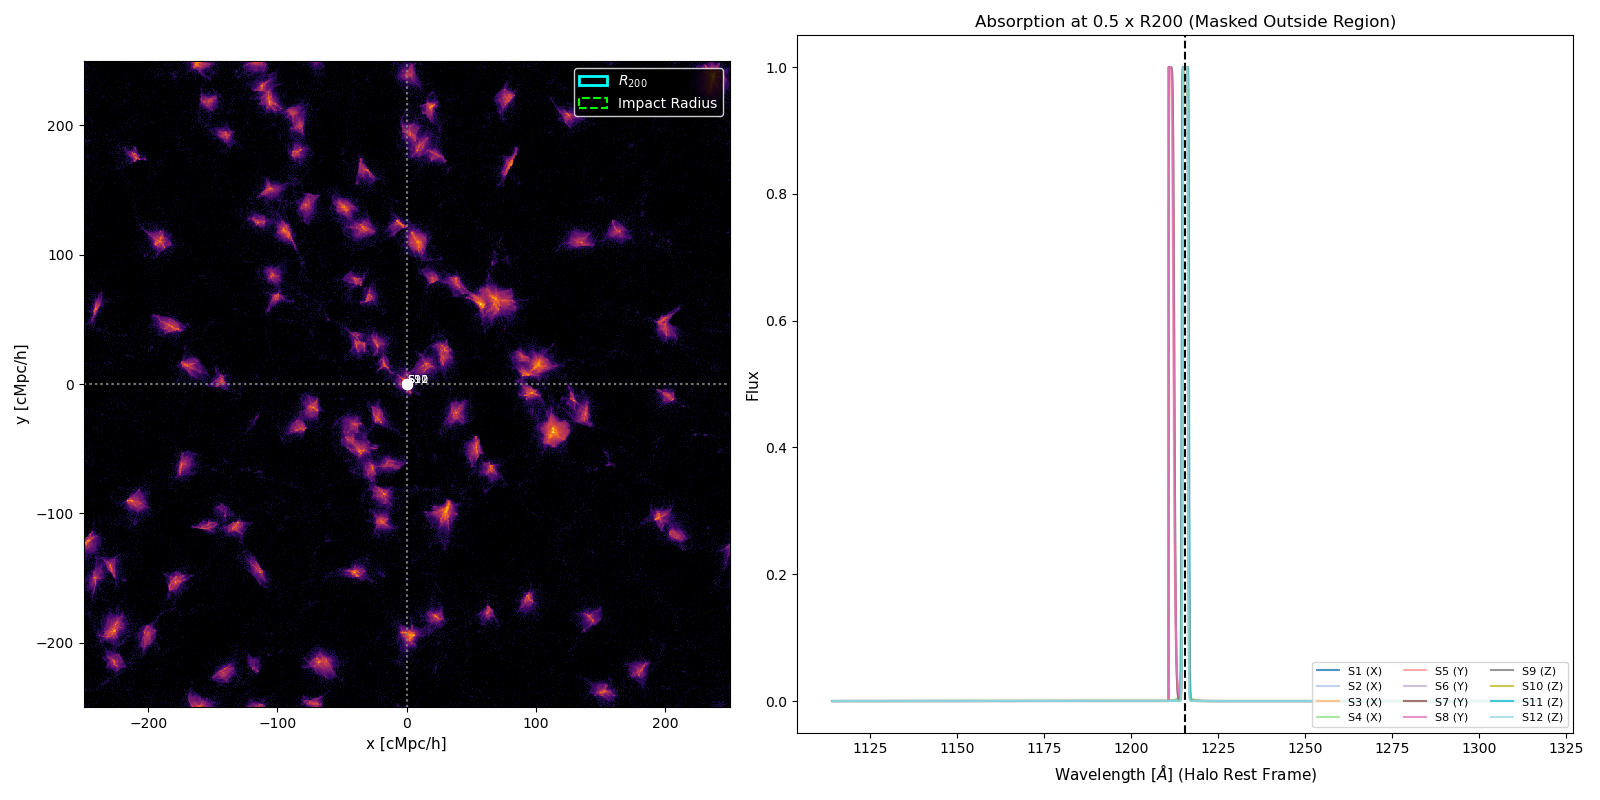

In [4]:
# --- 6. RODAR ANÁLISE DE ESPECTROS ---
print("--> Gerando espectros sintéticos...")
results = geom.run_analysis(skewers_list, center_mode='gas')

# --- 7. VISUALIZAÇÃO ---
print("--> Plotando...")
radii_skewers.RadiiVisualizer.plot_fullbox_overview(
    SIM_NAME, 
    halo_id, 
    geom.r200_mpc, 
    skewers_list[0]['impact_mpc'], 
    gas_map_centered, 
    results,
    box_size
)